## Machine Learning: Modelo Supervisado No 4. El Modelo CART

### Andrés Eduardo Rangel Jiménez


- Economista `(Universidad del Valle, Colombia)`

- MSc en Econometria `(Universidad Torcuato Di Tella, Argentina)`

- PhD en Dirección de Empresas `(Universidad de Valencia, España)`

Cada vez que cambias features o el flujo de datos:

  Kernel → Restart & Run All

  Nunca confiar en variables que quedaron
  de ejecuciones anteriores en memoria

In [145]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.inspection import DecisionBoundaryDisplay
import seaborn as sns
from sklearn.impute import KNNImputer
from sklearn.model_selection import  RandomizedSearchCV, cross_val_score
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, RocCurveDisplay
from sklearn import metrics
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import GridSearchCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (classification_report, confusion_matrix, 
                              roc_auc_score, roc_curve)
from sklearn.datasets import fetch_california_housing
import requests
import os
from pathlib import Path
from tqdm import tqdm
import pickle # Saving the model
import warnings ## to ignore waarning

### Modelos CART (Classification and Regression Tree)

```
Los algoritmos basados en árboles se consideran uno de los mejores y más utilizados métodos de machine learning supervisado. Estos algoritmos dotan a los modelos predictivos de alta precisión, estabilidad y facilidad de interpretación. A diferencia de los modelos lineales, capturan bastante bien las relaciones no lineales. Son adaptables para resolver cualquier tipo de problema (clasificación o regresión).

Métodos como los árboles de decisión, random forest y gradient boosting se utilizan ampliamente en todo tipo de problemas de ciencia de datos. Por lo tanto, para todo analista (incluso principiantes), es importante aprender estos algoritmos y usarlos en la modelación.

Este notebook tiene como objetivo ayudar a los estudiantes a aprender los algoritmos basados en árboles desde cero. Al completar exitosamente este notebook, se espera que ustedes sean competentes en el uso de estos algoritmos y en la construcción de modelos predictivos.

Los árboles de decisión (DT) son un método de aprendizaje supervisado no paramétrico utilizado para la clasificación y la regresión.
El nodo superior de un árbol de decisión se conoce como nodo raíz, luego en cada bifurcación se divide según una variable explicativa o prdictora  y cada nodo final contiene una predicción para la variable objetivo. El objetivo es crear un modelo que prediga el valor de una variable objetivo mediante el aprendizaje de reglas de decisión simples inferidas a partir de las características de los datos. Un árbol puede considerarse una aproximación constante por partes.

No necesita StandardScaler. Los arboles no calculan distancias entre puntos, solo hacen preguntas binarias del tipo trip_distance > 3.5?. La escala de las variables es irrelevante para ese proceso. Parte 5 del codigo es exclusiva de CART. El toDebugString te imprime las reglas exactas en texto legible — algo que KNN y Logit no pueden hacer de esta forma. La importancia de variables ademas te dira cuanto aporta cada una de las tres al modelo, que es directamente comparable con los coeficientes beta del Logit.


Estructura de árbol: CART construye una estructura similar a un árbol compuesta por nodos y ramas.  En el árbol de decisión, los nodos se dividen en subnodos según un valor umbral de algún atributo. Cada bifurcación se divide según una variable predictora y cada nodo final contiene una predicción para la variable objetivo

El nodo raíz se toma del conjunto de entrenamiento y se divide en dos considerando el mejor atributo y su valor umbral. Luego, los subconjuntos también se dividen usando la misma lógica. Este proceso continúa hasta que se encuentra el último subconjunto puro en el árbol o hasta alcanzar el número máximo de hojas permitido durante el crecimiento del árbol.

El término CART se usa como un término genérico para las siguientes categorías de árboles de decisión:

- Árboles de Clasificación: El árbol se utiliza para determinar a qué “clase” es más probable que pertenezca la variable objetivo cuando esta es categórica.

- Árboles de Regresión: Se utilizan para predecir el valor de una variable continua.

Algunas ventajas de los arboles de decision:

Requiere poca preparación de datos, no requiere estandarizacion. Otras técnicas suelen requerir la normalización de datos, la creación de variables ficticias y la eliminación de valores en blanco. Algunas combinaciones de árboles y algoritmos admiten valores faltantes.

¿Por qué CART no necesita estandarización?

El árbol toma decisiones con umbrales:
  "¿Age > 43?"      →  sí/no
  "¿Salary > 72000?" →  sí/no

Le importa el ORDEN de los valores, no su escala.
Da exactamente lo mismo comparar:
  Age > 43          que    Age_scaled > 1.2
El árbol llega al mismo split.


Utiliza un modelo de caja blanca. Si una situación dada es observable en un modelo, la explicación de la condición se explica fácilmente mediante lógica booleana. Por el contrario, en un modelo de caja negra (por ejemplo, en una red neuronal artificial), los resultados pueden ser más difíciles de interpretar.

Los aprendices de árboles de decisión crean árboles sesgados si algunas clases predominan. Por lo tanto, se recomienda equilibrar el conjunto de datos antes de ajustarlo al árbol de decisión.

### Modelos que requieren y no requieren estandarizacion
```
Modelos que NO necesitan estandarización:
  CART / Decision Tree   ← tu caso
  Random Forest
  Gradient Boosting
  XGBoost

Modelos que SÍ necesitan estandarización:
  KNN                    ← usa distancias euclidianas
  SVM                    ← usa distancias al hiperplano
  Regresión Logística    ← sensible a la escala

### Leyendo la base e datos del repositorio

In [72]:
# Configuración
DATA_DIR = "nyc_taxi_data"
Path(DATA_DIR).mkdir(parents=True, exist_ok=True)

# Archivo único: enero 2024
filename = "yellow_tripdata_2024-01.parquet"
url = f"https://d37ci6vzurychx.cloudfront.net/trip-data/{filename}"
destination = os.path.join(DATA_DIR, filename)

# Descargar si no existe
if os.path.exists(destination):
    file_size = os.path.getsize(destination) / (1024**3)
    print(f"✓ {filename} ya existe ({file_size:.2f} GB) — Saltando")
else:
    print(f" Descargando: {filename}")
    print(f" URL: {url}")

    response = requests.get(url, stream=True, timeout=30)
    response.raise_for_status()
    total_size = int(response.headers.get('content-length', 0))

    with open(destination, 'wb') as f:
        with tqdm(total=total_size, unit='B', unit_scale=True, desc=filename) as pbar:
            for chunk in response.iter_content(chunk_size=8192):
                if chunk:
                    f.write(chunk)
                    pbar.update(len(chunk))

    file_size = os.path.getsize(destination) / (1024**3)
    print(f"Descarga completada: {filename} ({file_size:.2f} GB)")

✓ yellow_tripdata_2024-01.parquet ya existe (0.05 GB) — Saltando


#### Cargamos base de datos

```
Los registros de viajes de los taxis amarillos y verdes incluyen campos que capturan las fechas y horas de recogida y llegada, los lugares de recogida y llegada, las distancias recorridas, las tarifas detalladas, los tipos de tarifa, los métodos de pago y el número de pasajeros reportado por el conductor.



In [74]:
datos = pd.read_parquet('yellow_tripdata_2024-01.parquet')
datos.head()

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee
0,2,2024-01-01 00:57:55,2024-01-01 01:17:43,1.0,1.72,1.0,N,186,79,2,17.7,1.0,0.5,0.00,0.0,1.0,22.70,2.5,0.0
1,1,2024-01-01 00:03:00,2024-01-01 00:09:36,1.0,1.80,1.0,N,140,236,1,10.0,3.5,0.5,3.75,0.0,1.0,18.75,2.5,0.0
2,1,2024-01-01 00:17:06,2024-01-01 00:35:01,1.0,4.70,1.0,N,236,79,1,23.3,3.5,0.5,3.00,0.0,1.0,31.30,2.5,0.0
3,1,2024-01-01 00:36:38,2024-01-01 00:44:56,1.0,1.40,1.0,N,79,211,1,10.0,3.5,0.5,2.00,0.0,1.0,17.00,2.5,0.0
4,1,2024-01-01 00:46:51,2024-01-01 00:52:57,1.0,0.80,1.0,N,211,148,1,7.9,3.5,0.5,3.20,0.0,1.0,16.10,2.5,0.0


In [8]:
datos.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2964624 entries, 0 to 2964623
Data columns (total 19 columns):
 #   Column                 Dtype         
---  ------                 -----         
 0   VendorID               int32         
 1   tpep_pickup_datetime   datetime64[us]
 2   tpep_dropoff_datetime  datetime64[us]
 3   passenger_count        float64       
 4   trip_distance          float64       
 5   RatecodeID             float64       
 6   store_and_fwd_flag     object        
 7   PULocationID           int32         
 8   DOLocationID           int32         
 9   payment_type           int64         
 10  fare_amount            float64       
 11  extra                  float64       
 12  mta_tax                float64       
 13  tip_amount             float64       
 14  tolls_amount           float64       
 15  improvement_surcharge  float64       
 16  total_amount           float64       
 17  congestion_surcharge   float64       
 18  Airport_fee           

In [10]:
datos.shape

(2964624, 19)

#### Objetivo. 

Deseamos construir un modelo que prediga si el cliente va a pagar con tarjeta de credito o en efectivo.

### Preparacion de los datos

#### 1.Chequeando la variable dependiente

```
Categorías de `payment_type` — NYC Yellow Taxi

| Código | Descripción                     |
|--------|---------------------------------|
| 1      | Credit card (tarjeta de crédito)|
| 2      | Cash (efectivo)                 |
| 3      | No charge (sin cobro)           |
| 4      | Dispute (disputa)               |
| 5      | Unknown (desconocido)           |
| 6      | Voided trip (viaje anulado)     |

In [16]:
print(datos['payment_type'].value_counts(normalize=True))

payment_type
1    0.782240
2    0.148144
0    0.047278
4    0.015728
3    0.006610
Name: proportion, dtype: float64


```
Para modelar la probabilidad de pagar con tarjeta, filtramos  solo 1 y 2 (recomendada)

In [76]:
# Filtrar solo pagos con tarjeta (1) y efectivo (2)
datos = datos[datos["payment_type"].isin([1, 2])].copy()

# Crear variable objetivo binaria
datos["card"] = (datos["payment_type"] == 1).astype(int)

In [71]:
print(datos['card'].value_counts(normalize=True))

card
1    0.840771
0    0.159229
Name: proportion, dtype: float64


#### 2. Creando las variables dicotomicas
```
Se crea  un indicador binario (0.0 = no es viaje a aeropuerto, valor > 0 = sí). Se convierte en dummy

In [78]:
datos["airport"] = (datos["Airport_fee"] > 0).astype(int)
print(datos['airport'].value_counts(normalize=True))

airport
0    0.917358
1    0.082642
Name: proportion, dtype: float64


#### Regla práctica según el desbalance

```
+---------------------------------+---------------------------------------+
| Proporción clase minoritaria    | ¿Balancear?                           |
+---------------------------------+---------------------------------------+
| > 35%                           | No suele ser necesario                |
| 20 - 35%                        | Opcional, probar ambas opciones       |
| 5 - 20%                         | Sí, recomendable                      |
| < 5%                            | Sí, prácticamente obligatorio         |
+---------------------------------+---------------------------------------+
```
```
 aquí conviene considerar algún tratamiento para balancear

#### Nota:
```

Si debes balancear,  nunca balancees antes de hacer el split train/test. Si lo haces, el test ya no refleja la distribución real de los datos en producción y tus métricas serán engañosas. El orden correcto es:

Split → train/test (con stratify=y para mantener la proporción).
Aplicar balanceo solo sobre el train.
Evaluar sobre el test sin tocar.

#### 3. Featuring engineer

```

Variable         Tipo original    Problema              Solución
---------------  ---------------  --------------------  -------------------------
PULocationID     int32 (código)   Categórica alta card. Target Encoding
DOLocationID     int32 (código)   Categórica alta card. Target Encoding
Airport_fee      float            Binaria implícita     Convertir a dummy (0/1)

Target Encoding — lógica:

PULocationID = 132 (JFK Airport)
  → en train, el 95% de viajes desde zona 132 pagan con tarjeta
  → se reemplaza 132 por 0.95

PULocationID = 74 (East Harlem)  
  → en train, el 71% pagan con tarjeta
  → se reemplaza 74 por 0.71


PULocationID y DOLocationID 

Son códigos de zona (1 a 265), no tienen orden matemático real — la zona 100 no es "más" que la zona 50. Entonces son categóricas de alta cardinalidad.
Con 265 categorías únicas, un One-Hot Encoding generaría 265 columnas por variable — costoso y disperso. Las mejores opciones son:

Técnica              Idea                                      Pros                        Contras
-------------------  ----------------------------------------  --------------------------  ---------------------------
Target Encoding      Reemplaza cada zona por la tasa media     Captura señal real,         Requiere hacerlo solo
                     de card=1 en esa zona                     una sola columna            con train

Frequency Encoding   Reemplaza por frecuencia de aparición     Simple, una columna         Menos informativo

One-Hot              Columna binaria por zona                  Interpretable               265+ columnas, lento

Dejarlas como int    Tratarlas como numéricas                  Nada que hacer              Matemáticamente incorrecto


Para CART con GridSearch → Target Encoding es lo más práctico.


#### Feature engineer: antes o despues del muestreo

```
 Depende de qué operación estés haciendo.

Operación                  Antes o después del muestreo   Razón
-------------------------  -----------------------------  ----------------------------------------
Airport_fee → dummy        Cualquiera de los dos          Es una transformación fija, no aprende
                                                          nada de los datos

Target Encoding            DESPUÉS del muestreo           Aprende estadísticas de los datos,
(PULocationID, DOLocationID)  y SOLO con train            si lo haces antes usas info de todo
                                                          el dataset → data leakage

One-Hot Encoding           Antes o después                Es fijo, pero después es más eficiente
                                                          pues trabajas con menos filas


Por esta razon las dos dicotomicas, card, variable dependiente y airport, explicativas se crearon antes de crear la muestra.

Regla práctica

Si la transformación APRENDE de los datos  →  después del split, solo con train
Si la transformación es FIJA               →  en cualquier momento, antes o después

#### Nota de rendimiento: 
```
Con ~2.7M filas, el GridSearchCV puede tardar mucho. Para iterar rápido, puedes trabajar con una muestra representativa y luego entrenar el modelo final sobre todo el conjunto:

### Flujo de trabajo
```

Muestra 20%  →  Split train/test  →  Target Encoding (solo con train)  →  Balanceo (solo en train)

### Paso 1:  Muestrea primero 
```
Al muestrear primero reduces el volumen antes de cualquier operación costosa.

Tomando una muestra: Una nota metodologica

Las muestras se toman diferente dependiendo si tengo o no una muestra balanceada

Método                        Estratificado   Garantía de proporción   Cuándo usarlo
----------------------------  --------------  -----------------------  ---------------------------
datos.sample(frac=0.2)        NO              No garantizada           Datasets grandes y balanceados
groupby().sample(frac=0.2)    SI              Garantizada por clase    Datasets desbalanceados

El metodo groupby().sample(frac=0.2)  se denomina metodo estratificado


Para el caso concreto: caso concreto (84% / 16%)

Dataset original:  2,758,237 filas
  card=1  →  2,318,876  (84%)
  card=0  →    439,361  (16%)

.sample(frac=0.2) sin estratificar:
  Muestra: ~551,647 filas
  Proporción real: no garantizada, puede variar por azar, un .sample() normal podría sacar una muestra con proporciones un poco distintas por azar
  (por ejemplo 82/18) diferente del desbalanceo real (84% tarjeta, 16% efectivo)


groupby().sample(frac=0.2) estratificado:
  card=1  →  463,775  (exactamente 20% de los card=1)
  card=0  →   87,872  (exactamente 20% de los card=0)
  Proporción: 84/16 garantizada



```
datos (2,691,342 filas, COMPLETO)
  │
  ├──► datos_muestra (20%, ~538,000 filas)   ← creada pero NUNCA USADA 
  │
  └──► X = datos[features]                   ← aquí pasa todo 
       y = datos['target']
         │
         └──► train_test_split → X_train (2.1M), X_test (538K)
                                   ↑ de los 2.7M completos

datos_muestra quedó como un objeto en memoria que nadie volvió a tocar.


In [80]:
## Con un desbalance de 84/16 la versión estratificada es la correcta:
datos_muestra = (
    datos.groupby('card', group_keys=False)
         .sample(frac=0.2, random_state=42)
         .reset_index(drop=True)
)
print(f"Muestra: {len(datos_muestra):,} filas")

Muestra: 551,647 filas


#### Forma 2 de obtener la muestra


```
Se usa la función de "dividir" para "samplear". Esta  es una práctica que aprovecha la función para otro propósito.

_, datos_muestra = train_test_split(
    datos,
    test_size=0.2,
    stratify=datos['card'],
    random_state=42
)
print(f"Muestra: {len(datos_muestra):,} filas")

train, test = train_test_split(datos, test_size=0.2)
train = 80% de los datos
test  = 20% de los datos

Devuelve dos conjuntos, sí o sí.
El "truco" que usamos
Cuando escribimos esto:

_, datos_muestra = train_test_split(datos, test_size=0.2, ...)

Lo que estamos diciendo es:

"Divide los datos en 80% y 20%".
"El 80% no me interesa, mándalo al basurero (_)".
"El 20% guárdalo en datos_muestra".

El guión bajo _ es una convención de Python para decir "esta variable no la voy a usar, tírala". Es decir, estamos aprovechando la función para conseguir el 20% y descartando la otra parte.




### Paso 2. FEATURES Y TARGET

In [82]:
# --- FEATURES Y TARGET ---
features = ["trip_distance", "fare_amount", "tip_amount",
            "tolls_amount", "total_amount", "passenger_count",
            "PULocationID", "DOLocationID", "airport"]

X = datos_muestra[features].copy()
y = datos_muestra["card"].copy()

In [42]:
X.head(12)

,trip_distance,fare_amount,tip_amount,tolls_amount,total_amount,passenger_count,PULocationID,DOLocationID,airport
0,2.29,17.7,0.0,0.0,21.7,4.0,230,68,0
1,0.78,7.9,0.0,0.0,14.4,1.0,107,79,0
2,0.50,5.1,0.0,0.0,9.1,1.0,12,88,0
3,2.19,14.9,0.0,0.0,19.9,1.0,141,170,0
4,1.30,10.0,0.0,0.0,15.0,3.0,144,87,0
5,2.41,12.1,0.0,0.0,17.1,1.0,233,79,0
6,8.57,38.0,0.0,0.0,42.0,3.0,243,162,0
7,2.88,17.0,0.0,0.0,21.0,1.0,239,140,0
8,0.89,7.2,0.0,0.0,11.2,1.0,161,234,0
9,0.50,6.5,0.0,0.0,10.5,1.0,140,141,0


### Paso 3. Split antes de balancear y del  target encoding para evitar data leakage

— el test set debe reflejar la distribución real del mundo (84/16).

In [84]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [46]:
X_test.tail()

,trip_distance,fare_amount,tip_amount,tolls_amount,total_amount,passenger_count,PULocationID,DOLocationID,airport
315840,4.12,23.3,5.00,0.00,32.30,1.0,161,42,0
142062,1.12,8.6,2.50,0.00,17.60,1.0,137,79,0
41435,8.43,-42.9,0.00,-6.94,-58.84,1.0,230,25,0
421088,2.79,23.3,6.83,0.00,34.13,1.0,43,239,0
288625,2.20,14.2,3.60,0.00,21.80,1.0,163,170,0


### Paso 4. Target Encoding  (calculado solo con train)

In [86]:
# PULocationID
pu_map = X_train.join(y_train).groupby("PULocationID")["card"].mean()
X_train["PULocationID_enc"] = X_train["PULocationID"].map(pu_map)
X_test["PULocationID_enc"]  = X_test["PULocationID"].map(pu_map).fillna(pu_map.mean())

# DOLocationID
do_map = X_train.join(y_train).groupby("DOLocationID")["card"].mean()
X_train["DOLocationID_enc"] = X_train["DOLocationID"].map(do_map)
X_test["DOLocationID_enc"]  = X_test["DOLocationID"].map(do_map).fillna(do_map.mean())

# ELIMINAR columnas originales de ID
X_train = X_train.drop(columns=["PULocationID", "DOLocationID"])
X_test  = X_test.drop(columns=["PULocationID", "DOLocationID"])

In [48]:
X_test.head()

,trip_distance,fare_amount,tip_amount,tolls_amount,total_amount,passenger_count,airport,PULocationID_enc,DOLocationID_enc
380332,1.90,11.4,3.25,0.0,19.65,1.0,0,0.852502,0.793218
374795,0.94,6.5,2.60,0.0,15.60,6.0,0,0.856906,0.793218
366346,0.66,13.5,0.00,0.0,17.50,1.0,0,0.849096,0.829773
539374,1.47,14.9,4.72,0.0,23.62,1.0,0,0.836358,0.772900
306001,1.10,7.2,2.20,0.0,13.40,1.0,0,0.845374,0.829966


In [50]:
X_train.head()

,trip_distance,fare_amount,tip_amount,tolls_amount,total_amount,passenger_count,airport,PULocationID_enc,DOLocationID_enc
396436,1.34,10.7,3.68,0.0,18.38,5.0,0,0.814457,0.880169
278267,0.68,6.5,1.00,0.0,11.50,1.0,0,0.841082,0.880169
243667,1.16,8.6,2.52,0.0,15.12,1.0,0,0.849417,0.855493
260411,0.00,90.0,0.00,0.0,93.50,4.0,0,0.800620,0.809293
402289,0.00,4.4,2.18,0.0,13.08,1.0,0,0.839348,0.871990


### Paso 5:  BALANCEO (solo sobre train)
```
Nota sobre el tipo de balanceo
Con 84/16 tienes dos opciones:

Si el desbalance es  60/40  →  50/50 es suficiente
Si el desbalance es  70/30  →  60/40 es suficiente
Si el desbalance es  80/20  →  70/30 es razonable      ← es nuestro caso aproximado
Si el desbalance es  90/10  →  75/25 o 70/30

In [88]:
# ── BALANCEO 70/30 (solo sobre train) ────────────────────────────────
train = X_train.copy()
train["card"] = y_train.values

# Separar clases
clase_1 = train[train["card"] == 1]
clase_0 = train[train["card"] == 0]

# Proporción deseada
proporcion_deseada = 0.30

n_clase_0 = len(clase_0)
n_clase_1 = int(n_clase_0 * (1 - proporcion_deseada) / proporcion_deseada)

# Undersample de clase mayoritaria
clase_1_bal = clase_1.sample(n=n_clase_1, random_state=42)

# Unir y mezclar
train_bal = pd.concat([clase_1_bal, clase_0]).sample(frac=1, random_state=42)

# Separar
X_train_bal = train_bal.drop(columns=["card"])
y_train_bal  = train_bal["card"]

print("Distribución tras balanceo:")
print(y_train_bal.value_counts(normalize=True))
print(f"\nShape train balanceado: {X_train_bal.shape}")
print(f"Shape test:             {X_test.shape}")

Distribución tras balanceo:
card
1    0.7
0    0.3
Name: proportion, dtype: float64

Shape train balanceado: (234233, 9)
Shape test:             (110330, 9)


In [95]:
X_train_bal.head()

,trip_distance,fare_amount,tip_amount,tolls_amount,total_amount,passenger_count,airport,PULocationID_enc,DOLocationID_enc
292955,1.13,9.3,1.0,0.0,14.30,1.0,0,0.859379,0.855493
16172,0.50,5.1,0.0,0.0,11.60,1.0,0,0.852502,0.848044
236010,2.62,17.0,5.0,0.0,27.00,2.0,0,0.859450,0.842194
320706,26.16,70.0,14.8,0.0,90.55,1.0,1,0.755390,0.862158
54029,0.90,7.2,0.0,0.0,13.70,1.0,0,0.859450,0.880169


#### Modelo Base y evaluación

BASELINE — DecisionTree (max_depth=3)
              precision    recall  f1-score   support

           0       0.81      1.00      0.90     17568
           1       1.00      0.96      0.98     92762

    accuracy                           0.96    110330
   macro avg       0.91      0.98      0.94    110330
weighted avg       0.97      0.96      0.97    110330

AUC-ROC:  0.9822
Accuracy: 0.9636


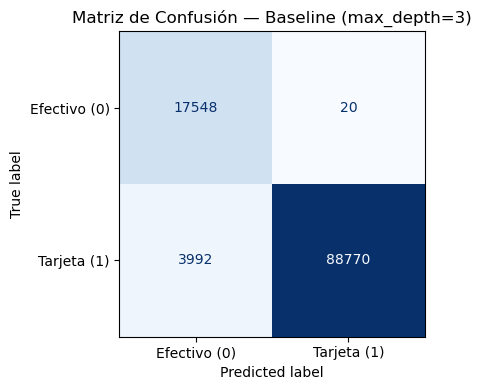

In [90]:
# ═══════════════════════════════════════════════════════
# PASO 1: Modelo base (baseline)
# ═══════════════════════════════════════════════════════
modelo_base = DecisionTreeClassifier(
    criterion='gini',
    max_depth=3,
    random_state=42
)
modelo_base.fit(X_train_bal, y_train_bal)

# Alinear X_test con las columnas del modelo entrenado
X_test_clean = X_test[X_train_bal.columns]

y_pred_base  = modelo_base.predict(X_test)
y_proba_base = modelo_base.predict_proba(X_test)[:, 1]

# ═══════════════════════════════════════════════════════
# PASO 2: Métricas baseline
# ═══════════════════════════════════════════════════════
print("=" * 50)
print("BASELINE — DecisionTree (max_depth=3)")
print("=" * 50)
print(classification_report(y_test, y_pred_base))
print(f"AUC-ROC:  {roc_auc_score(y_test, y_proba_base):.4f}")
print(f"Accuracy: {(y_pred_base == y_test).mean():.4f}")

# ═══════════════════════════════════════════════════════
# PASO 3: Matriz de confusión
# ═══════════════════════════════════════════════════════
cm = confusion_matrix(y_test, y_pred_base)

fig, ax = plt.subplots(figsize=(6, 4))
disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                               display_labels=["Efectivo (0)", "Tarjeta (1)"])
disp.plot(ax=ax, colorbar=False, cmap="Blues")
ax.set_title("Matriz de Confusión — Baseline (max_depth=3)", fontsize=12)
plt.tight_layout()
plt.show()

#### Soy un genio modelando o este modelo es sospechoso?. El problema del Data leakage

```

Sí, es sospechosamente bueno. Un AUC-ROC de 0.98 y Accuracy de 0.96 con solo max_depth=3 es una señal de alerta. Las causas más probables:

Síntoma                        Causa probable
-----------------------------  ----------------------------------------
AUC-ROC = 0.98 en baseline     "Data leakage"
Precision clase 1 = 1.00       Alguna variable predice perfectamente
Recall clase 0 = 1.00          el target de forma directa
Solo 20 falsos positivos

El sospechoso principal: tip_amount

tip_amount > 0   →  pago con tarjeta  (las propinas solo se registran en pagos electrónicos en NYC taxis)
tip_amount = 0   →  pago en efectivo


Esta variable no es un predictor, es una consecuencia directa del método de pago. Lo mismo puede pasar con total_amount que incluye el tip.


#### Data leakage
```
Data leakage ocurre cuando el modelo recibe durante el entrenamiento información que NO estaría disponible en el momento de hacer la predicción
en el mundo real.

Resultado: métricas artificialmente perfectas que no se replican cuando el modelo se despliega en producción.

PREGUNTA DEL MODELO:
  "¿Este pasajero va a pagar con tarjeta?"

LO QUE EL MODELO DEBERÍA VER:
  Información ANTES del pago:
  → distancia del viaje
  → zona de recogida
  → zona de destino
  → número de pasajeros
  → tarifa base

LO QUE NO DEBERÍA VER:
  Información que SOLO existe DESPUÉS de que el pago ocurrió:
  → tip_amount    ← la propina se registra AL MOMENTO de pagar con tarjeta
  → total_amount  ← incluye la propina, también contaminado

La relación causal

REALIDAD:
  Pasajero decide pagar con tarjeta  →  sistema registra tip_amount > 0
                     ↑                            ↑
                  CAUSA                        EFECTO

EL MODELO CON LEAKAGE LO INVIERTE:
  tip_amount > 0  →  predice card = 1
       ↑
  Está usando el EFECTO para predecir la CAUSA
  Es como adivinar que llovió porque el suelo está mojado

Por qué las métricas eran perfectas?

tip_amount = 0.00  →  card = 0  (efectivo)    casi sin excepciones
tip_amount > 0.00  →  card = 1  (tarjeta)     casi sin excepciones

El árbol con max_depth=3 solo necesitaba UNA pregunta:
  "¿tip_amount > 0?"
  SI  →  tarjeta   (correcto el 99% de las veces)
  NO  →  efectivo  (correcto el 99% de las veces)

Resultado: AUC-ROC = 0.98  con un árbol de profundidad 3
           No es inteligencia del modelo, es trampa.

Analogía

Examen de admisión a una universidad:

  CON LEAKAGE:    el modelo sabe si el estudiante se graduó
                  para predecir si va a ser admitido
                  → predice perfecto, pero es inútil en la práctica

  SIN LEAKAGE:    el modelo solo sabe notas, puntajes, experiencia
                  ANTES de la decisión de admisión
                  → métricas más bajas pero resultado honesto y útil

Resumen ejecutivo

CON tip_amount:     AUC-ROC = 0.98  ← trampa, modelo inútil en producción
SIN tip_amount:     AUC-ROC = 0.59  ← honesto, punto de partida real

El GridSearch trabajará sobre 0.59 para mejorarlo legítimamente.


#### Verificando Data leakage
```
La forma de verificar nuestras sospechas es ver importancia de variables, muy probablemente tip_amount aparece con importancia cercana a 1.0.

In [92]:
# Ver importancia de variables
importancias = pd.Series(
    modelo_base.feature_importances_,
    index=X_train_bal.columns
).sort_values(ascending=False)

print(importancias)

tip_amount          0.979086
PULocationID_enc    0.017566
fare_amount         0.002906
total_amount        0.000442
trip_distance       0.000000
tolls_amount        0.000000
passenger_count     0.000000
airport             0.000000
DOLocationID_enc    0.000000
dtype: float64


```
Confirmado. tip_amount con 0.979 de importancia es data leakage puro.

tip_amount    = 0.979  ← LEAKAGE: consecuencia directa del pago con tarjeta
PULocationID  = 0.017  ← predictor legítimo
fare_amount   = 0.002  ← predictor legítimo
total_amount  = 0.000  ← LEAKAGE: incluye el tip
trip_distance = 0.000  ← predictor legítimo pero opacado por tip
tolls_amount  = 0.000  ← predictor legítimo pero opacado por tip
passenger_count = 0.000
airport         = 0.000
DOLocationID  = 0.000

### Acción: redefine las features excluyendo las contaminadas

In [101]:
# Excluir tip_amount y total_amount
#comenta
features = [
    "trip_distance",
    "fare_amount",
    "tolls_amount",
    "passenger_count",
    "PULocationID_enc",
    "DOLocationID_enc",
    "airport"
]

In [ ]:
Luego repite todo el flujo desde el split:

In [103]:
# ── 1. FEATURES SIN ENCODING (columnas originales) ──────────────────
features = [
    "trip_distance", "fare_amount", "tolls_amount",
    "passenger_count", "PULocationID", "DOLocationID", "airport"
]

X = datos_muestra[features].copy()
y = datos_muestra["card"].copy()

# ── 2. SPLIT ─────────────────────────────────────────────────────────
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# ── 3. TARGET ENCODING (calculado SOLO con train) ────────────────────
pu_map = X_train.join(y_train).groupby("PULocationID")["card"].mean()
X_train["PULocationID_enc"] = X_train["PULocationID"].map(pu_map)
X_test["PULocationID_enc"]  = X_test["PULocationID"].map(pu_map).fillna(pu_map.mean())

do_map = X_train.join(y_train).groupby("DOLocationID")["card"].mean()
X_train["DOLocationID_enc"] = X_train["DOLocationID"].map(do_map)
X_test["DOLocationID_enc"]  = X_test["DOLocationID"].map(do_map).fillna(do_map.mean())

X_train = X_train.drop(columns=["PULocationID", "DOLocationID"])
X_test  = X_test.drop(columns=["PULocationID", "DOLocationID"])

# ── 4. BALANCEO (solo sobre train) ───────────────────────────────────
train = X_train.copy()
train["card"] = y_train.values
clase_1 = train[train["card"] == 1]
clase_0 = train[train["card"] == 0]
n_clase_1 = int(len(clase_0) * 0.70 / 0.30)
clase_1_bal = clase_1.sample(n=n_clase_1, random_state=42)
train_bal = pd.concat([clase_1_bal, clase_0]).sample(frac=1, random_state=42)
X_train_bal = train_bal.drop(columns=["card"])
y_train_bal  = train_bal["card"]

print("Distribución tras balanceo:")
print(y_train_bal.value_counts(normalize=True))
print(f"\nShape train: {X_train_bal.shape}")
print(f"Shape test:  {X_test.shape}")

Distribución tras balanceo:
card
1    0.7
0    0.3
Name: proportion, dtype: float64

Shape train: (234233, 7)
Shape test:  (110330, 7)


#### Reestimo otra vez el modelo base

BASELINE — DecisionTree (max_depth=3)
              precision    recall  f1-score   support

           0       0.50      0.09      0.16     17568
           1       0.85      0.98      0.91     92762

    accuracy                           0.84    110330
   macro avg       0.68      0.54      0.53    110330
weighted avg       0.80      0.84      0.79    110330

AUC-ROC:  0.5914
Accuracy: 0.8410


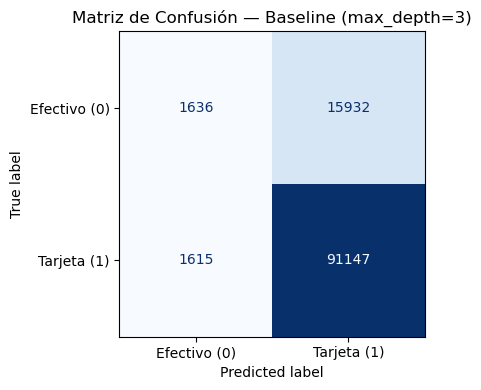

In [105]:
# ═══════════════════════════════════════════════════════
# PASO 1: Modelo base (baseline)
# ═══════════════════════════════════════════════════════
modelo_base = DecisionTreeClassifier(
    criterion='gini',
    max_depth=3,
    random_state=42
)
modelo_base.fit(X_train_bal, y_train_bal)

y_pred_base  = modelo_base.predict(X_test)
y_proba_base = modelo_base.predict_proba(X_test)[:, 1]

# ═══════════════════════════════════════════════════════
# PASO 2: Métricas baseline
# ═══════════════════════════════════════════════════════
print("=" * 50)
print("BASELINE — DecisionTree (max_depth=3)")
print("=" * 50)
print(classification_report(y_test, y_pred_base))
print(f"AUC-ROC:  {roc_auc_score(y_test, y_proba_base):.4f}")
print(f"Accuracy: {(y_pred_base == y_test).mean():.4f}")

# ═══════════════════════════════════════════════════════
# PASO 3: Matriz de confusión
# ═══════════════════════════════════════════════════════
cm = confusion_matrix(y_test, y_pred_base)

fig, ax = plt.subplots(figsize=(6, 4))
disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                               display_labels=["Efectivo (0)", "Tarjeta (1)"])
disp.plot(ax=ax, colorbar=False, cmap="Blues")
ax.set_title("Matriz de Confusión — Baseline (max_depth=3)", fontsize=12)
plt.tight_layout()
plt.show()

```
Ahora sí nuestro resultado es mas real y  honesto. Analicemos:

DIAGNÓSTICO BASELINE
==================================================
Métrica          Clase 0 (Efectivo)   Clase 1 (Tarjeta)
---------------  -------------------  -----------------
Precision        0.50                 0.85
Recall           0.09                 0.98
F1-score         0.16                 0.91

AUC-ROC: 0.59   ← apenas mejor que un modelo aleatorio (0.50)
Accuracy: 0.84  ← engañosa, refleja solo que el 84% paga con tarjeta

Problemas identificados:

1. Recall clase 0 = 0.09  →  el modelo casi no detecta pagos en efectivo
                              de 17,568 efectivos, solo clasifica 1,581
                              correctamente

2. AUC-ROC = 0.59         →  muy cercano a 0.50 (clasificador aleatorio)
                              el árbol con max_depth=3 es demasiado simple

3. Accuracy = 0.84        →  no es informativa aquí, es simplemente
                              la proporción de la clase mayoritaria

Conclusión: el baseline es débil → hay mucho margen de mejora
            el GridSearch debería mejorar especialmente:
            - AUC-ROC  (objetivo principal)
            - Recall clase 0  (detectar pagos en efectivo)

#### Fine tuning con GridSearchCV
```
+---------------------+----------------------------------------------+
| Hiperparámetro      | Qué controla                                 |
+---------------------+----------------------------------------------+
| max_depth           | Profundidad máxima (evita sobreajuste)       |
| min_samples_split   | Mínimo de muestras para dividir un nodo      |
| min_samples_leaf    | Mínimo de muestras por hoja                  |
| criterion           | Gini o entropía                              |
| max_features        | Cuántas features considerar por split        |
| ccp_alpha           | Poda por complejidad (cost complexity)       |
+---------------------+----------------------------------------------+

In [107]:
from sklearn.model_selection import GridSearchCV
from sklearn.tree import DecisionTreeClassifier

parametros = {
    'max_depth'        : [4, 6, 8, 12],
    'min_samples_split': [20, 100, 500],
    'min_samples_leaf' : [10, 50],
    'criterion'        : ['gini', 'entropy'],
}

grid = GridSearchCV(
    estimator=DecisionTreeClassifier(random_state=42),
    param_grid=parametros,
    scoring='roc_auc',
    cv=5,
    n_jobs=-1,
    verbose=1
)

grid.fit(X_train_bal, y_train_bal)

print("Mejores hiperparámetros:", grid.best_params_)
print(f"Mejor AUC-ROC (CV):     {grid.best_score_:.4f}")

Fitting 5 folds for each of 48 candidates, totalling 240 fits
Mejores hiperparámetros: {'criterion': 'gini', 'max_depth': 12, 'min_samples_leaf': 10, 'min_samples_split': 500}
Mejor AUC-ROC (CV):     0.6343


```
Combinaciones: 4 × 3 × 2 × 2 = 48 combinaciones × 5 folds = 240 entrenamientos.

#### Inspeccionar los resultados después

```
Esto te muestra las 10 mejores combinaciones con su F1 promedio, desviación estándar entre folds y tiempo de entrenamiento. Muy útil porque a veces la diferencia entre el mejor y el segundo mejor es mínima, y puedes preferir el más simple (menor max_depth) aunque tenga 0.001 menos de F1.



In [126]:
resultados = pd.DataFrame(grid.cv_results_)[[
    'params', 'mean_test_score', 'std_test_score', 'rank_test_score', 'mean_fit_time'
]].sort_values('rank_test_score').head(10)

print("Top 10 combinaciones:")
print(resultados)

Top 10 combinaciones:
                                               params  mean_test_score  \
20  {'criterion': 'gini', 'max_depth': 12, 'min_sa...         0.634277   
23  {'criterion': 'gini', 'max_depth': 12, 'min_sa...         0.634180   
44  {'criterion': 'entropy', 'max_depth': 12, 'min...         0.633951   
47  {'criterion': 'entropy', 'max_depth': 12, 'min...         0.633750   
36  {'criterion': 'entropy', 'max_depth': 8, 'min_...         0.633266   
37  {'criterion': 'entropy', 'max_depth': 8, 'min_...         0.633220   
19  {'criterion': 'gini', 'max_depth': 12, 'min_sa...         0.632736   
13  {'criterion': 'gini', 'max_depth': 8, 'min_sam...         0.632721   
12  {'criterion': 'gini', 'max_depth': 8, 'min_sam...         0.632653   
39  {'criterion': 'entropy', 'max_depth': 8, 'min_...         0.632613   

    std_test_score  rank_test_score  mean_fit_time  
20        0.003532                1       0.385516  
23        0.003317                2       0.368052  
44  

#### COMPARACIÓN CONTROLADA: balanceo manual vs class_weight

In [109]:
# ═══════════════════════════════════════════════════════
# Misma métrica (roc_auc), mismos hiperparámetros
# ═══════════════════════════════════════════════════════

parametros = {
    'max_depth'        : [4, 6, 8, 12],
    'min_samples_split': [20, 100, 500],
    'min_samples_leaf' : [10, 50],
    'criterion'        : ['gini', 'entropy'],
}

# ── OPCIÓN A: balanceo manual 70/30 (ya lo tienes) ───────────────────
grid_bal = GridSearchCV(
    estimator=DecisionTreeClassifier(random_state=42),
    param_grid=parametros,
    scoring='roc_auc',
    cv=5,
    n_jobs=-1,
    verbose=0
)
grid_bal.fit(X_train_bal, y_train_bal)

# ── OPCIÓN B: class_weight='balanced' ────────────────────────────────
grid_cw = GridSearchCV(
    estimator=DecisionTreeClassifier(class_weight='balanced', random_state=42),
    param_grid=parametros,
    scoring='roc_auc',
    cv=5,
    n_jobs=-1,
    verbose=0
)
grid_cw.fit(X_train, y_train)

# ── EVALUACIÓN SOBRE EL MISMO X_test ─────────────────────────────────
X_test_clean = X_test[X_train_bal.columns]

y_proba_bal = grid_bal.best_estimator_.predict_proba(X_test_clean)[:, 1]
y_proba_cw  = grid_cw.best_estimator_.predict_proba(X_test_clean)[:, 1]

# ── RESULTADOS ────────────────────────────────────────────────────────
print("=" * 60)
print(f"{'':25} {'Balanceo manual':>15} {'class_weight':>15}")
print("=" * 60)
print(f"{'Mejor AUC-ROC (CV)':<25} {grid_bal.best_score_:>15.4f} {grid_cw.best_score_:>15.4f}")
print(f"{'AUC-ROC (test)':<25} {roc_auc_score(y_test, y_proba_bal):>15.4f} {roc_auc_score(y_test, y_proba_cw):>15.4f}")
print("-" * 60)
print(f"{'max_depth':<25} {grid_bal.best_params_['max_depth']:>15} {grid_cw.best_params_['max_depth']:>15}")
print(f"{'criterion':<25} {grid_bal.best_params_['criterion']:>15} {grid_cw.best_params_['criterion']:>15}")
print(f"{'min_samples_split':<25} {grid_bal.best_params_['min_samples_split']:>15} {grid_cw.best_params_['min_samples_split']:>15}")
print(f"{'min_samples_leaf':<25} {grid_bal.best_params_['min_samples_leaf']:>15} {grid_cw.best_params_['min_samples_leaf']:>15}")
print("=" * 60)

                          Balanceo manual    class_weight
Mejor AUC-ROC (CV)                 0.6343          0.6352
AUC-ROC (test)                     0.6351          0.6351
------------------------------------------------------------
max_depth                              12              12
criterion                            gini         entropy
min_samples_split                     500             500
min_samples_leaf                       10              10


#### Conclusión

```
AUC-ROC (test) es IDÉNTICO: 0.6351 en ambos casos

Los dos métodos son equivalentes en rendimiento predictivo.
La diferencia en CV es de 0.0009 → despreciable.


Balanceo manual 70/30     =     class_weight='balanced'

Ambos le dicen al árbol lo mismo:
"presta más atención a la clase minoritaria"

Solo cambia el mecanismo:
  manual      →  reduce físicamente la clase mayoritaria
  class_weight →  aumenta el costo de equivocarse en la minoritaria

### Evaluacion el modelo final sobre el test set:

COMPARACIÓN FINAL DE MODELOS
Métrica                     Baseline   GridSearch
------------------------------------------------------------
AUC-ROC                       0.5914       0.6351
Accuracy                      0.8410       0.8364
max_depth                          3           12
criterion                       gini         gini

GRID SEARCH — Reporte completo
              precision    recall  f1-score   support

Efectivo (0)       0.46      0.15      0.22     17568
 Tarjeta (1)       0.86      0.97      0.91     92762

    accuracy                           0.84    110330
   macro avg       0.66      0.56      0.56    110330
weighted avg       0.79      0.84      0.80    110330



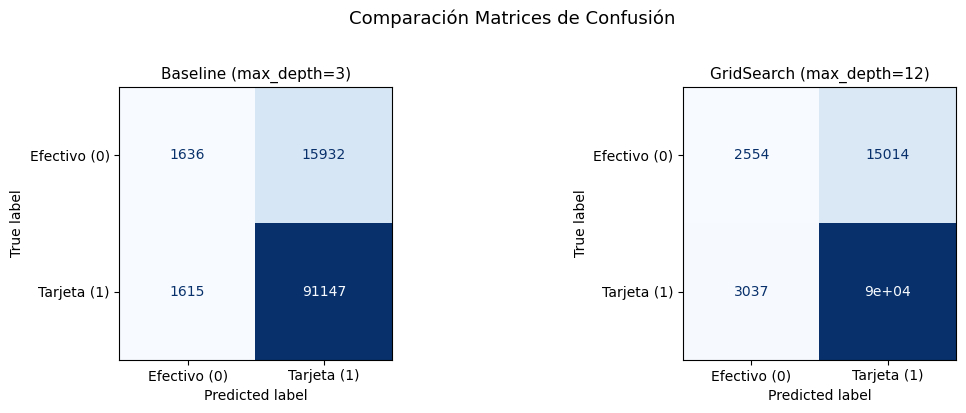

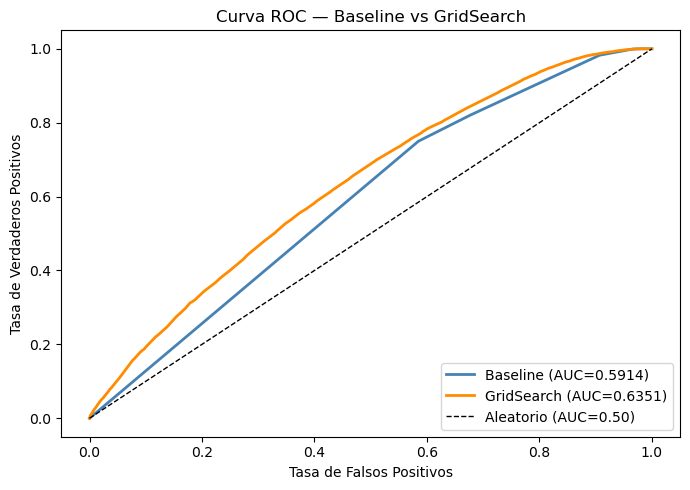

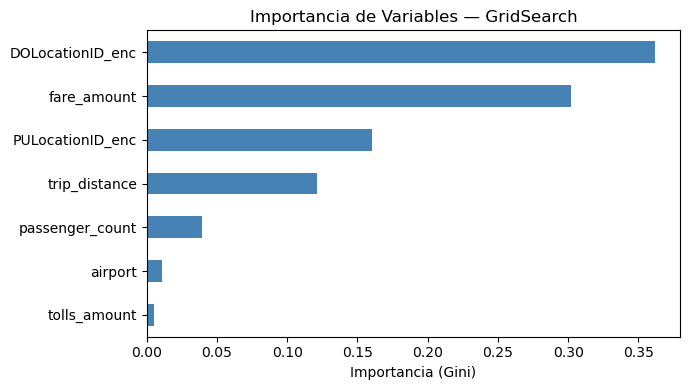

In [111]:
# ═══════════════════════════════════════════════════════
# EVALUACIÓN FINAL — COMPARACIÓN DE LOS TRES MODELOS
# ═══════════════════════════════════════════════════════

modelo_final = grid_bal.best_estimator_

y_pred_final  = modelo_final.predict(X_test_clean)
y_proba_final = modelo_final.predict_proba(X_test_clean)[:, 1]

# ── TABLA COMPARATIVA ────────────────────────────────────────────────
print("=" * 60)
print("COMPARACIÓN FINAL DE MODELOS")
print("=" * 60)
print(f"{'Métrica':<25} {'Baseline':>10} {'GridSearch':>12}")
print("-" * 60)
print(f"{'AUC-ROC':<25} {roc_auc_score(y_test, y_proba_base):>10.4f} {roc_auc_score(y_test, y_proba_final):>12.4f}")
print(f"{'Accuracy':<25} {(y_pred_base == y_test).mean():>10.4f} {(y_pred_final == y_test).mean():>12.4f}")
print(f"{'max_depth':<25} {'3':>10} {str(grid_bal.best_params_['max_depth']):>12}")
print(f"{'criterion':<25} {'gini':>10} {grid_bal.best_params_['criterion']:>12}")
print("=" * 60)

# ── REPORTE COMPLETO GRIDSEARCH ───────────────────────────────────────
print("\nGRID SEARCH — Reporte completo")
print("=" * 60)
print(classification_report(y_test, y_pred_final,
      target_names=["Efectivo (0)", "Tarjeta (1)"]))

# ── MATRICES DE CONFUSIÓN COMPARATIVAS ───────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, y_pred, titulo in zip(
    axes,
    [y_pred_base, y_pred_final],
    ["Baseline (max_depth=3)", f"GridSearch (max_depth={grid_bal.best_params_['max_depth']})"]
):
    cm = confusion_matrix(y_test, y_pred)
    ConfusionMatrixDisplay(confusion_matrix=cm,
                           display_labels=["Efectivo (0)", "Tarjeta (1)"]).plot(
        ax=ax, colorbar=False, cmap="Blues"
    )
    ax.set_title(titulo, fontsize=11)

plt.suptitle("Comparación Matrices de Confusión", fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

# ── CURVA ROC COMPARATIVA ─────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(7, 5))

for y_proba, label, color in zip(
    [y_proba_base, y_proba_final],
    [f"Baseline (AUC={roc_auc_score(y_test, y_proba_base):.4f})",
     f"GridSearch (AUC={roc_auc_score(y_test, y_proba_final):.4f})"],
    ["steelblue", "darkorange"]
):
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    ax.plot(fpr, tpr, label=label, color=color, lw=2)

ax.plot([0, 1], [0, 1], "k--", lw=1, label="Aleatorio (AUC=0.50)")
ax.set_xlabel("Tasa de Falsos Positivos")
ax.set_ylabel("Tasa de Verdaderos Positivos")
ax.set_title("Curva ROC — Baseline vs GridSearch")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

# ── IMPORTANCIA DE VARIABLES ──────────────────────────────────────────
importancias = pd.Series(
    modelo_final.feature_importances_,
    index=X_test_clean.columns
).sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(7, 4))
importancias.plot(kind="barh", ax=ax, color="steelblue")
ax.set_title("Importancia de Variables — GridSearch")
ax.set_xlabel("Importancia (Gini)")
plt.tight_layout()
plt.show()

#### Visualizacion

```
Nota: max_depth=3 aquí solo controla cuántos niveles se grafican, no cambia el modelo entrenado. Útil si el árbol real tiene max_depth=8 y se ve ilegible.

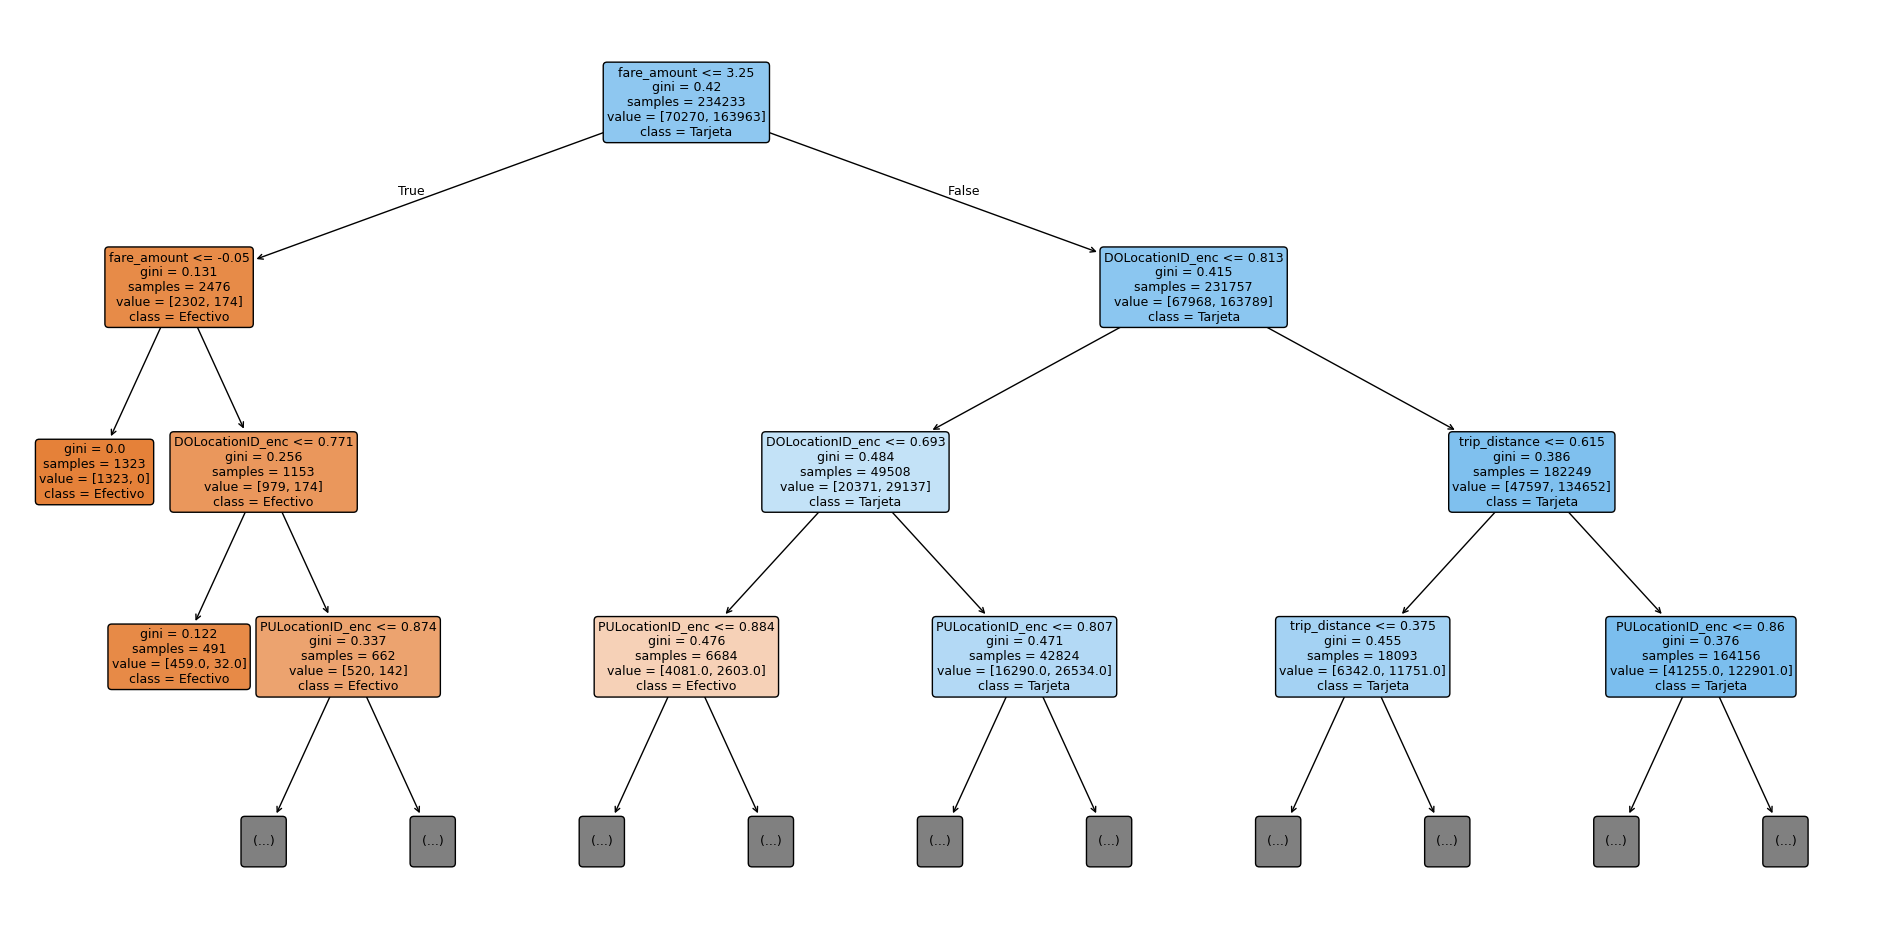

In [129]:
# Si el max_depth ganador es pequeño (ej. 6), se puede visualizar completo
plt.figure(figsize=(24, 12))
plot_tree(
    modelo_final,
    feature_names=X_train.columns.tolist(),
    class_names=['Efectivo', 'Tarjeta'],
    filled=True,
    rounded=True,
    fontsize=9,
    max_depth=3   # limita la profundidad del DIBUJO (no del modelo)
)
plt.show()

In [132]:
import pandas as pd
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
)

# === 1) Función que calcula todas las métricas ===
def calcular_metricas(y_true, y_pred, y_proba):
    return {
        'Accuracy':           accuracy_score(y_true, y_pred),
        'Precision Efectivo': precision_score(y_true, y_pred, pos_label=0),
        'Recall Efectivo':    recall_score(y_true, y_pred, pos_label=0),
        'F1 Efectivo':        f1_score(y_true, y_pred, pos_label=0),
        'Precision Tarjeta':  precision_score(y_true, y_pred, pos_label=1),
        'Recall Tarjeta':     recall_score(y_true, y_pred, pos_label=1),
        'F1 Tarjeta':         f1_score(y_true, y_pred, pos_label=1),
        'F1 Macro':           f1_score(y_true, y_pred, average='macro'),
        'F1 Weighted':        f1_score(y_true, y_pred, average='weighted'),
        'ROC-AUC':            roc_auc_score(y_true, y_proba),
    }

# === 2) Calcular métricas de cada modelo ===
metricas_base  = calcular_metricas(y_test, y_pred_base,  y_proba_base)
metricas_final = calcular_metricas(y_test, y_pred_final, y_proba_final)

# === 3) Armar tabla comparativa con mejora absoluta y relativa (%) ===
comparacion = pd.DataFrame({
    'Modelo Base':  metricas_base,
    'Modelo Final': metricas_final,
})
comparacion['Mejora Absoluta'] = comparacion['Modelo Final'] - comparacion['Modelo Base']
comparacion['Mejora %'] = (
    (comparacion['Modelo Final'] - comparacion['Modelo Base'])
    / comparacion['Modelo Base'].replace(0, 1e-9)
) * 100

comparacion = comparacion.round(4)

print("=" * 70)
print("COMPARACIÓN MODELO BASE vs MODELO FINAL (5 features)")
print("=" * 70)
print(comparacion)

COMPARACIÓN MODELO BASE vs MODELO FINAL (5 features)
                    Modelo Base  Modelo Final  Mejora Absoluta  Mejora %
Accuracy                 0.8410        0.8364          -0.0046   -0.5432
Precision Efectivo       0.5032        0.4568          -0.0464   -9.2252
Recall Efectivo          0.0931        0.1454           0.0523   56.1125
F1 Efectivo              0.1572        0.2206           0.0634   40.3388
Precision Tarjeta        0.8512        0.8567           0.0054    0.6392
Recall Tarjeta           0.9826        0.9673          -0.0153   -1.5601
F1 Tarjeta               0.9122        0.9086          -0.0036   -0.3938
F1 Macro                 0.5347        0.5646           0.0299    5.5927
F1 Weighted              0.7920        0.7990           0.0071    0.8933
ROC-AUC                  0.5914        0.6351           0.0437    7.3851


#### Conclusiones — Modelo CART: Baseline vs GridSearch

```

CONTEXTO: predecir si un pasajero paga con tarjeta (card=1)
          o en efectivo (card=0) — NYC Yellow Taxi 2024
          Sin data leakage (tip_amount y total_amount excluidas)


1. MEJORA REAL PERO MODERADA EN DISCRIMINACIÓN

Esta es la métrica más honesta y te está diciendo algo incómodo:

+----------+------------------------------------+
| ROC-AUC  | Interpretación                     |
+----------+------------------------------------+
| 0.50     | Modelo aleatorio (tirar una moneda)|
| 0.60     | Muy débil                          |
| 0.70     | Aceptable                          |
| 0.80     | Bueno                              |
| 0.90+    | Excelente                          |
+----------+------------------------------------+

   AUC-ROC:  0.5914  →  0.6351  (+0.0437, +7.4%)
ROC-AUC: métrica robusta al desbalance (es la más honesta para comparar modelos).

   El GridSearch mejora la capacidad discriminatoria del modelo
   en 7.4 puntos porcentuales. Sigue siendo un AUC modesto,
   lo que indica que las variables disponibles (distancia,
   tarifa, zonas) tienen poder predictivo limitado sobre
   el método de pago.

2. EL GRIDSEARCH MEJORA LO QUE MÁS IMPORTA: DETECTAR EFECTIVO
qué porcentaje de los viajes en efectivo reales detectaste.

   Recall Efectivo:  0.0931  →  0.1454  (+56.1%)

   El baseline casi no detectaba pagos en efectivo — de cada
   100 pagos reales en efectivo, solo identificaba 9.
   El modelo final identifica 15. Aún bajo, pero es la mejora
   más significativa del ejercicio.

3. LA ACCURACY ES ENGAÑOSA — NO ES LA MÉTRICA RELEVANTE

   Accuracy:  0.8410  →  0.8364  (-0.5%)

   La accuracy baja levemente porque el modelo final intenta
   detectar más pagos en efectivo, cometiendo más errores
   en la clase mayoritaria. Esto es esperado y deseable
   cuando el objetivo es mejorar el recall de la clase
   minoritaria.

4. TRADE-OFF CLÁSICO PRECISION vs RECALL EN CLASE MINORITARIA

   Precision Efectivo:  0.5032  →  0.4568  (-9.2%)
   Recall Efectivo:     0.0931  →  0.1454  (+56.1%)

   Al detectar más pagos en efectivo, el modelo comete
   más falsos positivos — clasifica como efectivo algunos
   pagos que son realmente con tarjeta. Es el trade-off
   clásico: ganar recall cuesta precision.

5. LA CLASE MAYORITARIA SE MANTIENE ESTABLE

   F1 Tarjeta:  0.9122  →  0.9086  (-0.4%)

   La capacidad de predecir pagos con tarjeta prácticamente
   no cambia. El GridSearch redistribuye el esfuerzo del
   modelo sin perjudicar significativamente la clase dominante.

6. F1 MACRO: LA MÉTRICA MÁS HONESTA

   F1 Macro:  0.5347  →  0.5646  (+5.6%)

   Al promediar ambas clases por igual, el F1 Macro confirma
   que el GridSearch produce un modelo globalmente mejor,
   más equilibrado entre las dos clases.

CONCLUSIÓN GENERAL

   El GridSearch con CART logra una mejora legítima y honesta
   sobre el baseline. La ganancia no es espectacular porque
   las variables disponibles — distancia, tarifa, zonas —
   tienen correlación limitada con el método de pago cuando
   se elimina el data leakage.

   Esto es un resultado válido y defendible: un modelo
   con AUC-ROC de 0.63 construido con variables limpias
   es más útil en producción que un modelo con AUC-ROC
   de 0.98 construido con data leakage.

La "mejora" se concentró en la clase mayoritaria. En el fondo, el modelo no está aprendiendo a distinguir realmente entre efectivo y tarjeta.
Diagnóstico: ¿por qué el modelo es tan débil?
Esto apunta a que las features que estás usando tienen poco poder predictivo para este problema. Variables como fare_amount, trip_distance, hour, passenger_count probablemente no contienen señal suficiente para saber si alguien pagó con tarjeta o efectivo. Piénsalo: el método de pago depende más de el pasajero individual que de las características del viaje.

#### Gini index/Gini impurity

El índice de Gini es una métrica para las tareas de clasificación en CART. Almacena la suma de las probabilidades al cuadrado de cada clase. Calcula el grado de probabilidad de que una variable específica sea clasificada erróneamente cuando se elige al azar, y es una variación del coeficiente de Gini. Funciona con variables categóricas, proporciona resultados de tipo “éxito” o “fracaso” y, por lo tanto, solo realiza divisiones binarias.

El valor del índice de Gini varía entre 0 y 1:

El índice de Gini mide qué tan “mezclados” están los datos en un nodo de un árbol de decisión.
- Si en un nodo todas las observaciones son de la misma clase, la impureza es 0 (perfectamente puro).
  
- Si en un nodo las clases están muy mezcladas, la impureza se acerca a 1 (muy impuro).

- Un valor de 1 – 1/n ocurre cuando los elementos están distribuidos uniformemente en n clases y cada clase tiene la misma probabilidad de 1/n. Por ejemplo, con dos clases, la impureza de Gini es 1-(1/2)=0,5 


#### Ejercicio 2

In [127]:
## Importación de la base
datos=pd.read_csv("Social_Network_Ads.csv")
datos.head()

,User ID,Gender,Age,EstimatedSalary,Purchased
0,15624510,Male,19,19000,0
1,15810944,Male,35,20000,0
2,15668575,Female,26,43000,0
3,15603246,Female,27,57000,0
4,15804002,Male,19,76000,0


In [129]:
datos.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   User ID          400 non-null    int64 
 1   Gender           400 non-null    object
 2   Age              400 non-null    int64 
 3   EstimatedSalary  400 non-null    int64 
 4   Purchased        400 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 15.8+ KB


In [131]:
print(datos['Purchased'].value_counts(normalize=True))

Purchased
0    0.6425
1    0.3575
Name: proportion, dtype: float64


In [133]:
###Separemos la base entre covariables y etiqueta
x = datos.iloc[:,2:4]
y = datos.iloc[:,-1]

In [135]:
# Split the data into training and test sets
X_train,X_test,y_train,y_test = train_test_split(x,y,test_size = 0.2,random_state=42)

Fitting 5 folds for each of 72 candidates, totalling 360 fits
Mejores hiperparámetros: {'criterion': 'gini', 'max_depth': 5, 'min_samples_leaf': 10, 'min_samples_split': 2}
Mejor AUC-ROC (CV):     0.9517

Métrica                       Baseline   GridSearch
AUC-ROC                         0.9584       0.9629
Accuracy                        0.9125       0.9000
-------------------------------------------------------
max_depth                            3            5
criterion                         gini         gini
min_samples_split                    2            2
min_samples_leaf                     1           10

BASELINE — Reporte completo
               precision    recall  f1-score   support

No compra (0)       0.96      0.90      0.93        52
   Compra (1)       0.84      0.93      0.88        28

     accuracy                           0.91        80
    macro avg       0.90      0.92      0.91        80
 weighted avg       0.92      0.91      0.91        80


GRID SEARCH 

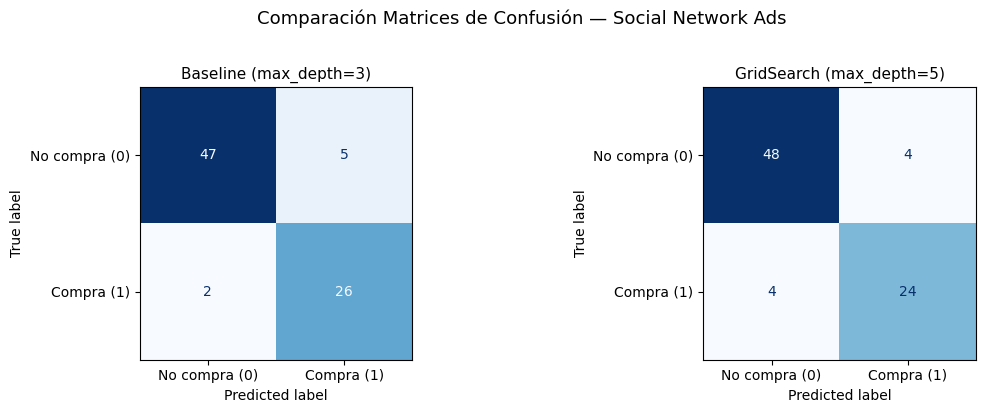

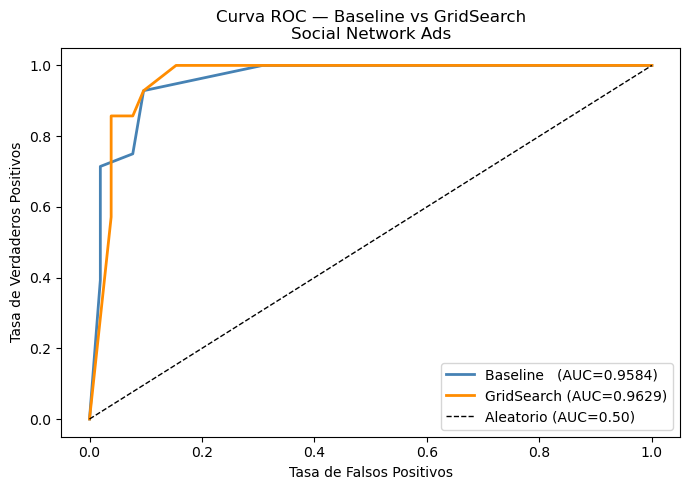

In [137]:
# ═══════════════════════════════════════════════════════
# MODELO BASE (baseline)
# ═══════════════════════════════════════════════════════
modelo_base = DecisionTreeClassifier(
    criterion='gini',
    max_depth=3,
    random_state=42
)
modelo_base.fit(X_train, y_train)

y_pred_base  = modelo_base.predict(X_test)
y_proba_base = modelo_base.predict_proba(X_test)[:, 1]

# ═══════════════════════════════════════════════════════
# GRID SEARCH
# ═══════════════════════════════════════════════════════
parametros = {
    'max_depth'        : [3, 5, 7, 10],
    'min_samples_split': [2, 10, 20],
    'min_samples_leaf' : [1, 5, 10],
    'criterion'        : ['gini', 'entropy'],
}

grid = GridSearchCV(
    estimator=DecisionTreeClassifier(random_state=42),
    param_grid=parametros,
    scoring='roc_auc',
    cv=5,
    n_jobs=-1,
    verbose=1
)
grid.fit(X_train, y_train)

print("Mejores hiperparámetros:", grid.best_params_)
print(f"Mejor AUC-ROC (CV):     {grid.best_score_:.4f}")

# ═══════════════════════════════════════════════════════
# MODELO FINAL
# ═══════════════════════════════════════════════════════
modelo_final  = grid.best_estimator_
y_pred_final  = modelo_final.predict(X_test)
y_proba_final = modelo_final.predict_proba(X_test)[:, 1]

# ═══════════════════════════════════════════════════════
# COMPARACIÓN DE MÉTRICAS
# ═══════════════════════════════════════════════════════
from sklearn.metrics import (classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, roc_auc_score)

print("\n" + "=" * 55)
print(f"{'Métrica':<25} {'Baseline':>12} {'GridSearch':>12}")
print("=" * 55)
print(f"{'AUC-ROC':<25} {roc_auc_score(y_test, y_proba_base):>12.4f} {roc_auc_score(y_test, y_proba_final):>12.4f}")
print(f"{'Accuracy':<25} {(y_pred_base == y_test).mean():>12.4f} {(y_pred_final == y_test).mean():>12.4f}")
print("-" * 55)
print(f"{'max_depth':<25} {'3':>12} {str(grid.best_params_['max_depth']):>12}")
print(f"{'criterion':<25} {'gini':>12} {grid.best_params_['criterion']:>12}")
print(f"{'min_samples_split':<25} {'2':>12} {str(grid.best_params_['min_samples_split']):>12}")
print(f"{'min_samples_leaf':<25} {'1':>12} {str(grid.best_params_['min_samples_leaf']):>12}")
print("=" * 55)

print("\nBASELINE — Reporte completo")
print(classification_report(y_test, y_pred_base,
      target_names=["No compra (0)", "Compra (1)"]))

print("\nGRID SEARCH — Reporte completo")
print(classification_report(y_test, y_pred_final,
      target_names=["No compra (0)", "Compra (1)"]))

# ═══════════════════════════════════════════════════════
# MATRICES DE CONFUSIÓN COMPARATIVAS
# ═══════════════════════════════════════════════════════
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, y_pred, titulo in zip(
    axes,
    [y_pred_base, y_pred_final],
    ["Baseline (max_depth=3)",
     f"GridSearch (max_depth={grid.best_params_['max_depth']})"]
):
    cm = confusion_matrix(y_test, y_pred)
    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["No compra (0)", "Compra (1)"]
    ).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(titulo, fontsize=11)

plt.suptitle("Comparación Matrices de Confusión — Social Network Ads",
             fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

# ═══════════════════════════════════════════════════════
# CURVA ROC COMPARATIVA
# ═══════════════════════════════════════════════════════
from sklearn.metrics import roc_curve

fig, ax = plt.subplots(figsize=(7, 5))

for y_proba, label, color in zip(
    [y_proba_base, y_proba_final],
    [f"Baseline   (AUC={roc_auc_score(y_test, y_proba_base):.4f})",
     f"GridSearch (AUC={roc_auc_score(y_test, y_proba_final):.4f})"],
    ["steelblue", "darkorange"]
):
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    ax.plot(fpr, tpr, label=label, color=color, lw=2)

ax.plot([0, 1], [0, 1], "k--", lw=1, label="Aleatorio (AUC=0.50)")
ax.set_xlabel("Tasa de Falsos Positivos")
ax.set_ylabel("Tasa de Verdaderos Positivos")
ax.set_title("Curva ROC — Baseline vs GridSearch\nSocial Network Ads")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

Ahora teniendo en cuenta el desbalanceo

Fitting 5 folds for each of 72 candidates, totalling 360 fits
Mejores hiperparámetros: {'criterion': 'gini', 'max_depth': 5, 'min_samples_leaf': 10, 'min_samples_split': 2}
Mejor AUC-ROC (CV):     0.9525

Métrica                       Baseline   GridSearch
AUC-ROC                         0.9423       0.9560
Accuracy                        0.9125       0.9125
-------------------------------------------------------
max_depth                            3            5
criterion                         gini         gini
min_samples_split                    2            2
min_samples_leaf                     1           10

BASELINE — Reporte completo
               precision    recall  f1-score   support

No compra (0)       0.96      0.90      0.93        52
   Compra (1)       0.84      0.93      0.88        28

     accuracy                           0.91        80
    macro avg       0.90      0.92      0.91        80
 weighted avg       0.92      0.91      0.91        80


GRID SEARCH 

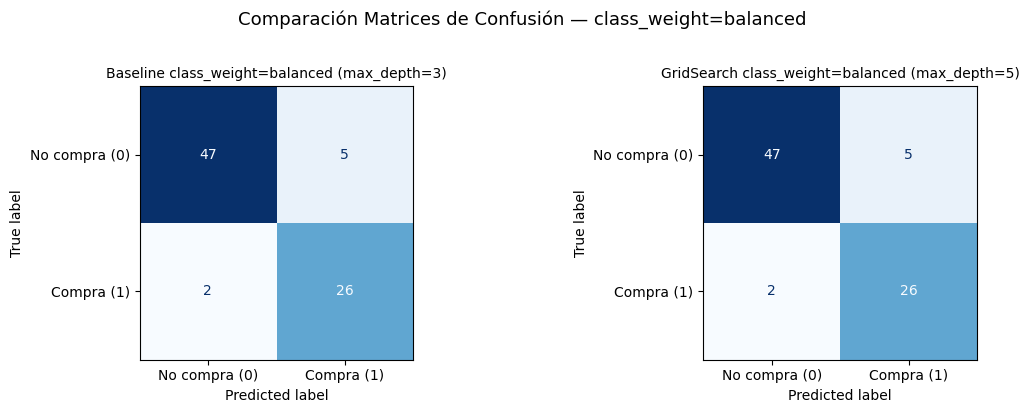

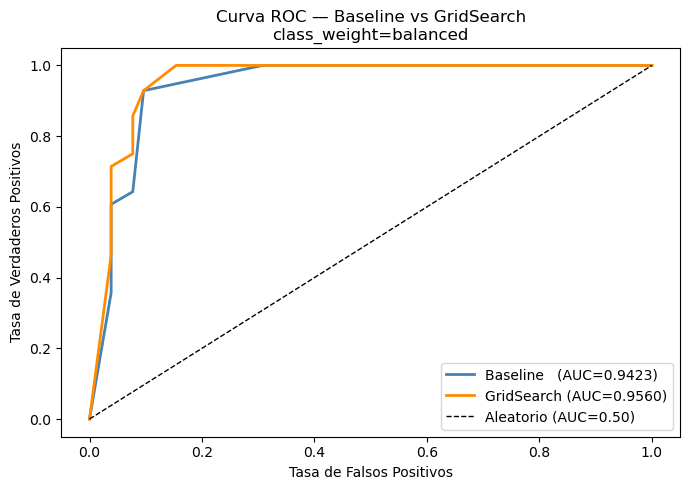

In [179]:
# ═══════════════════════════════════════════════════════
# MODELO BASE CON class_weight='balanced'
# ═══════════════════════════════════════════════════════
modelo_base = DecisionTreeClassifier(
    criterion='gini',
    max_depth=3,
    class_weight='balanced',
    random_state=42
)
modelo_base.fit(X_train, y_train)

y_pred_base  = modelo_base.predict(X_test)
y_proba_base = modelo_base.predict_proba(X_test)[:, 1]

# ═══════════════════════════════════════════════════════
# GRID SEARCH CON class_weight='balanced'
# ═══════════════════════════════════════════════════════
parametros = {
    'max_depth'        : [3, 5, 7, 10],
    'min_samples_split': [2, 10, 20],
    'min_samples_leaf' : [1, 5, 10],
    'criterion'        : ['gini', 'entropy'],
}

grid = GridSearchCV(
    estimator=DecisionTreeClassifier(
        class_weight='balanced',
        random_state=42
    ),
    param_grid=parametros,
    scoring='roc_auc',
    cv=5,
    n_jobs=-1,
    verbose=1
)
grid.fit(X_train, y_train)

print("Mejores hiperparámetros:", grid.best_params_)
print(f"Mejor AUC-ROC (CV):     {grid.best_score_:.4f}")

# ═══════════════════════════════════════════════════════
# MODELO FINAL
# ═══════════════════════════════════════════════════════
modelo_final  = grid.best_estimator_
y_pred_final  = modelo_final.predict(X_test)
y_proba_final = modelo_final.predict_proba(X_test)[:, 1]

# ═══════════════════════════════════════════════════════
# COMPARACIÓN DE MÉTRICAS
# ═══════════════════════════════════════════════════════
print("\n" + "=" * 55)
print(f"{'Métrica':<25} {'Baseline':>12} {'GridSearch':>12}")
print("=" * 55)
print(f"{'AUC-ROC':<25} {roc_auc_score(y_test, y_proba_base):>12.4f} {roc_auc_score(y_test, y_proba_final):>12.4f}")
print(f"{'Accuracy':<25} {(y_pred_base == y_test).mean():>12.4f} {(y_pred_final == y_test).mean():>12.4f}")
print("-" * 55)
print(f"{'max_depth':<25} {'3':>12} {str(grid.best_params_['max_depth']):>12}")
print(f"{'criterion':<25} {'gini':>12} {grid.best_params_['criterion']:>12}")
print(f"{'min_samples_split':<25} {'2':>12} {str(grid.best_params_['min_samples_split']):>12}")
print(f"{'min_samples_leaf':<25} {'1':>12} {str(grid.best_params_['min_samples_leaf']):>12}")
print("=" * 55)

print("\nBASELINE — Reporte completo")
print(classification_report(y_test, y_pred_base,
      target_names=["No compra (0)", "Compra (1)"]))

print("\nGRID SEARCH — Reporte completo")
print(classification_report(y_test, y_pred_final,
      target_names=["No compra (0)", "Compra (1)"]))

# ═══════════════════════════════════════════════════════
# MATRICES DE CONFUSIÓN COMPARATIVAS
# ═══════════════════════════════════════════════════════
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, y_pred, titulo in zip(
    axes,
    [y_pred_base, y_pred_final],
    ["Baseline class_weight=balanced (max_depth=3)",
     f"GridSearch class_weight=balanced (max_depth={grid.best_params_['max_depth']})"]
):
    cm = confusion_matrix(y_test, y_pred)
    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["No compra (0)", "Compra (1)"]
    ).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(titulo, fontsize=10)

plt.suptitle("Comparación Matrices de Confusión — class_weight=balanced",
             fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

# ═══════════════════════════════════════════════════════
# CURVA ROC COMPARATIVA
# ═══════════════════════════════════════════════════════
fig, ax = plt.subplots(figsize=(7, 5))

for y_proba, label, color in zip(
    [y_proba_base, y_proba_final],
    [f"Baseline   (AUC={roc_auc_score(y_test, y_proba_base):.4f})",
     f"GridSearch (AUC={roc_auc_score(y_test, y_proba_final):.4f})"],
    ["steelblue", "darkorange"]
):
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    ax.plot(fpr, tpr, label=label, color=color, lw=2)

ax.plot([0, 1], [0, 1], "k--", lw=1, label="Aleatorio (AUC=0.50)")
ax.set_xlabel("Tasa de Falsos Positivos")
ax.set_ylabel("Tasa de Verdaderos Positivos")
ax.set_title("Curva ROC — Baseline vs GridSearch\nclass_weight=balanced")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

### Usando arboles de decision para regresion

In [141]:
from sklearn.datasets import fetch_california_housing
california = fetch_california_housing()
print(california.DESCR)

.. _california_housing_dataset:

California Housing dataset
--------------------------

**Data Set Characteristics:**

:Number of Instances: 20640

:Number of Attributes: 8 numeric, predictive attributes and the target

:Attribute Information:
    - MedInc        median income in block group
    - HouseAge      median house age in block group
    - AveRooms      average number of rooms per household
    - AveBedrms     average number of bedrooms per household
    - Population    block group population
    - AveOccup      average number of household members
    - Latitude      block group latitude
    - Longitude     block group longitude

:Missing Attribute Values: None

This dataset was obtained from the StatLib repository.
https://www.dcc.fc.up.pt/~ltorgo/Regression/cal_housing.html

The target variable is the median house value for California districts,
expressed in hundreds of thousands of dollars ($100,000).

This dataset was derived from the 1990 U.S. census, using one row per ce

In [161]:
# Cargar los datos
california = fetch_california_housing()

# Crear el DataFrame con los datos y nombres de columnas
df = pd.DataFrame(california.data, columns=california.feature_names)

# Agregar la variable objetivo al final
df["Target"] = california.target

# Ver las primeras filas

df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,Target
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [163]:
from sklearn.model_selection import train_test_split
SEED = 11  

X_train, X_test, y_train, y_test = train_test_split(california.data,
                                                    california.target, test_size=0.25, random_state=SEED)
print(X_train.shape)
print(X_test.shape)

(15480, 8)
(5160, 8)


In [167]:
# 1. Importar librerías
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

# Crear el modelo
tree_regressor = DecisionTreeRegressor(random_state=42)

# Entrenar el modelo
tree_regressor.fit(X_train, y_train)

# Predecir sobre datos de prueba
y_pred = tree_regressor.predict(X_test)

# Evaluar el rendimiento
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Error cuadrático medio (MSE): {mse:.2f}")
print(f"R² Score: {r2:.2f}")

Error cuadrático medio (MSE): 0.52
R² Score: 0.62


In [169]:
df=pd.DataFrame({'Actual':y_test, 'Predicted':y_pred})
df.head(5)

,Actual,Predicted
0,0.762,0.808
1,1.732,1.401
2,1.125,2.250
3,1.370,1.380
4,1.856,2.046


In [171]:
from sklearn import metrics
print('Mean Absolute Error:', metrics.mean_absolute_error(y_test,y_pred))
print('Mean Squared Error:', metrics.mean_squared_error(y_test,y_pred))
print('Root Mean Squared Error:', np.sqrt(metrics.mean_squared_error(y_test,y_pred)))
print('r2_score:', metrics.r2_score(y_test,y_pred))

Mean Absolute Error: 0.4642842984496124
Mean Squared Error: 0.5154089859650776
Root Mean Squared Error: 0.7179199021931887
r2_score: 0.6155236672075918


In [154]:
importancias = pd.Series(tree_regressor.feature_importances_, 
                         index=california.feature_names)
importancias = importancias.sort_values(ascending=False)

print(importancias)

MedInc        0.520550
AveOccup      0.129348
Latitude      0.096472
Longitude     0.096066
HouseAge      0.053334
AveRooms      0.048781
Population    0.031718
AveBedrms     0.023730
dtype: float64


In [156]:
from sklearn.model_selection import GridSearchCV
param_grid = [{"max_depth":[1,2, 3,4,5, 6], "max_features":[1,2,3,4,5]}]
gs = GridSearchCV(estimator=DecisionTreeRegressor(random_state=123),param_grid = param_grid,cv=10)
gs.fit(X_train, y_train)

,estimator,DecisionTreeR...dom_state=123)
,param_grid,"[{'max_depth': [1, 2, ...], 'max_features': [1, 2, ...]}]"
,scoring,None
,n_jobs,None
,refit,True
,cv,10
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,criterion,'squared_error'


In [157]:
gs.cv_results_['rank_test_score']

array([30, 28, 26, 25, 26, 29, 19, 23, 20, 13, 24, 18, 17, 16,  9, 22, 15,
        8, 11,  5, 21, 12,  6,  7,  2, 14, 10,  4,  3,  1], dtype=int32)

In [158]:
gs.cv_results_['params']

[{'max_depth': 1, 'max_features': 1},
 {'max_depth': 1, 'max_features': 2},
 {'max_depth': 1, 'max_features': 3},
 {'max_depth': 1, 'max_features': 4},
 {'max_depth': 1, 'max_features': 5},
 {'max_depth': 2, 'max_features': 1},
 {'max_depth': 2, 'max_features': 2},
 {'max_depth': 2, 'max_features': 3},
 {'max_depth': 2, 'max_features': 4},
 {'max_depth': 2, 'max_features': 5},
 {'max_depth': 3, 'max_features': 1},
 {'max_depth': 3, 'max_features': 2},
 {'max_depth': 3, 'max_features': 3},
 {'max_depth': 3, 'max_features': 4},
 {'max_depth': 3, 'max_features': 5},
 {'max_depth': 4, 'max_features': 1},
 {'max_depth': 4, 'max_features': 2},
 {'max_depth': 4, 'max_features': 3},
 {'max_depth': 4, 'max_features': 4},
 {'max_depth': 4, 'max_features': 5},
 {'max_depth': 5, 'max_features': 1},
 {'max_depth': 5, 'max_features': 2},
 {'max_depth': 5, 'max_features': 3},
 {'max_depth': 5, 'max_features': 4},
 {'max_depth': 5, 'max_features': 5},
 {'max_depth': 6, 'max_features': 1},
 {'max_depth

In [159]:
print(gs.best_estimator_)

DecisionTreeRegressor(max_depth=6, max_features=5, random_state=123)


In [160]:
tree = DecisionTreeRegressor(max_depth=6,max_features=5)

In [161]:
tree.fit(X_train, y_train)

,criterion,'squared_error'
,splitter,'best'
,max_depth,6
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,5
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,ccp_alpha,0.0


In [162]:
predictions = tree.predict(X_test)

In [163]:
df=pd.DataFrame({'Actual':y_test, 'Predicted':predictions})
df.head(5) #Check the top 5 predictions and actual values.

,Actual,Predicted
0,0.762,1.661167
1,1.732,1.864558
2,1.125,2.291100
3,1.370,1.864558
4,1.856,2.039947


In [172]:
from sklearn import metrics
print('Mean Absolute Error:', metrics.mean_absolute_error(y_test,predictions))
print('Mean Squared Error:', metrics.mean_squared_error(y_test,predictions))
print('Root Mean Squared Error:', np.sqrt(metrics.mean_squared_error(y_test,predictions)))
print('r2_score:', metrics.r2_score(y_test,predictions))

Mean Absolute Error: 0.5227921071748597
Mean Squared Error: 0.510661582235568
Root Mean Squared Error: 0.7146058929476918
r2_score: 0.6190650574935781
